# DQN para LunarLander-v3

Implementación del algoritmo Deep Q-Learning (DQN) con TensorFlow/Keras para el entorno **LunarLander-v3** de Gymnasium, adaptada a partir de una implementación base para CartPole.

## Autor

| Nombre | Correo electrónico |
|---|---|
| Jorge López | jorgelpdz05@gmail.com |


## Librerías

Se instala `gymnasium[box2d]` en lugar de `gymnasium[classic-control]`, ya que el entorno LunarLander-v3 pertenece a la colección Box2D de Gymnasium, que requiere el motor de física Box2D. El resto de dependencias (`tensorflow`/`keras`, `numpy`, `matplotlib`) están listadas en `requirements.txt`.

In [1]:
!pip install gymnasium[box2d]

import gymnasium as gym
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt
import time
import random
import math

## Hiperparámetros

LunarLander-v3 es un entorno significativamente más complejo que CartPole:
- **8 observaciones** (posición x/y, velocidades, ángulo, velocidad angular, contacto de cada pata)
- **4 acciones** discretas (no hacer nada, motor izquierdo, motor principal, motor derecho)
- Recompensas **continuas y con valores negativos** (penalización por combustible, movimientos bruscos...)

La tabla compara la implementación base para CartPole con la **configuración final** usada en este notebook (celda «Configuración final»):

| Parámetro | Base (CartPole) | Final (LunarLander) | Justificación |
|---|---|---|---|
| `LEARNING_RATE` | 0.001 | 0.00063 | Pasos de gradiente más conservadores ante recompensas ruidosas |
| `BATCH_SIZE` | 64 | 128 | Menor varianza del gradiente con una red más grande |
| `GAMMA` | 0.99 | 0.99 | Sin cambio: el descenso debe planificarse con mucha antelación |
| `MEMORY_SIZE` | 100000 | 100000 | Sin cambio |
| `EXPLORATION_RATE_MIN` | 0.01 | 0.05 | Mantiene una exploración residual hasta el final |
| `EXPLORATION_RATE_DECAY` | 0.98 | 0.985 | Decaimiento algo más lento: más exploración inicial |
| `MAX_EPISODES_FOR_TRAINING` | 600 | 1000 | Cota superior de seguridad |
| `TRAINING_GOAL` | 400 | 230 | Margen sobre el umbral de 200 puntos de LunarLander |
| `EPISODES_TO_CHECK_TRAINING_GOAL` | 10 | 20 | Media más estable del rendimiento reciente |
| `TRAINING_FREQ` | N/A | 4 | **Nuevo:** `learn()` solo se ejecuta cada 4 pasos de entorno |
| `TARGET_UPDATE_STEPS` | N/A | 500 | **Nuevo:** la red objetivo se actualiza cada 500 pasos de entorno |

Tras el entrenamiento, el modelo se evalúa con `EPISODES_TO_EVALUATE_MODEL_PERFORMANCE = 30` episodios.

### Análisis detallado de cada parámetro

**`LEARNING_RATE`: 0.001 → 0.00063**

En CartPole el espacio de observación es pequeño y la recompensa es simple (+1 por paso). En LunarLander las señales son mucho más ruidosas y heterogéneas: penalización por combustible (cada disparo del motor principal resta 0.3 puntos), penalización por movimientos bruscos y recompensas escasas de aterrizaje (+100/+140). Un learning rate alto hace que Adam dé actualizaciones grandes que pueden desestabilizar lo aprendido. El valor 0.00063 está inspirado en la configuración de referencia de RL Baselines3 Zoo para DQN en LunarLander y produce actualizaciones más conservadoras.

**`BATCH_SIZE`: 64 → 128**

El gradiente calculado sobre un batch es una estimación estadística del gradiente real. Con batches pequeños esa estimación tiene mayor varianza. Al doblar el tamaño a 128 se promedia sobre más transiciones, lo que es especialmente importante con la red de 256-256 neuronas: en las pruebas, batches de 64 con esta red generaban gradientes demasiado ruidosos (ver «Cambios probados que produjeron resultados insatisfactorios»).

**`GAMMA`: 0.99 (sin cambio)**

El factor de descuento controla cuánto valora el agente las recompensas futuras. En LunarLander la trayectoria de descenso debe planificarse mucho antes del aterrizaje, por lo que 0.99 es un valor adecuado. Con un gamma bajo el agente sería «miope» y daría poca importancia a aterrizar correctamente.

**`MEMORY_SIZE`: 100 000 (sin cambio)**

El replay buffer almacena las últimas 100 000 transiciones, unos 240 episodios de ~410 pasos. En la ejecución final el entrenamiento terminó con 84 481 transiciones (incluido el warm-up), por lo que el buffer no llegó a llenarse; aun así, el buffer es circular para que entrenamientos más largos sobrescriban correctamente las transiciones más antiguas.

**`EXPLORATION_RATE_DECAY`: 0.98 → 0.985 y `EXPLORATION_RATE_MIN`: 0.01 → 0.05**

La tasa de exploración ε se multiplica por el decay al final de cada episodio. Con 0.985, ε llega al mínimo de 0.05 en unos 198 episodios (0.985^198 ≈ 0.05); con 0.98 llegaría en unos 150, demasiado pronto para LunarLander, donde el agente necesita ver suficiente diversidad de estados antes de comprometerse con una política (ver apartado 3 de «Cambios probados»). Decays aún más lentos (0.997, 0.999) retrasaban el aprendizaje útil. El mínimo de 0.05 mantiene una exploración residual hasta el final del entrenamiento.

**`MAX_EPISODES_FOR_TRAINING`: 600 → 1000**

Cota superior de seguridad: la mayor complejidad del entorno puede requerir más episodios. En la ejecución final el criterio de parada se alcanzó en 195 episodios.

**`TRAINING_GOAL`: 400 → 230 y `EPISODES_TO_CHECK_TRAINING_GOAL`: 10 → 20**

LunarLander-v3 se considera resuelto con una media de al menos 200 puntos. El objetivo de entrenamiento se fija en 230 para dejar un margen de seguridad: la media de los últimos episodios de entrenamiento (con exploración residual y entorno estocástico) puede no coincidir exactamente con la media de la evaluación posterior con política greedy. Además, LunarLander tiene mucha variabilidad entre episodios, por lo que se promedian los últimos 20 en lugar de 10 para evitar paradas prematuras por un falso positivo.

**`TRAINING_FREQ`: N/A → 4 (nuevo)**

`learn()` solo se ejecuta una vez cada 4 interacciones con el entorno. Así, entre dos actualizaciones consecutivas el buffer acumula transiciones nuevas, lo que reduce la correlación temporal entre batches, y disminuye el tiempo de CPU por episodio, ya que el paso de gradiente es la operación más costosa. El valor 4 sigue la frecuencia de actualización del paper original de DQN (Mnih et al., 2015).

**`TARGET_UPDATE_STEPS`: N/A → 500 (nuevo)**

Cada 500 pasos de entorno se copian los pesos de la red principal a la red objetivo (actualización «dura»). Actualizar con demasiada frecuencia hace que los Q-targets sean casi tan inestables como sin red objetivo; actualizar con poca frecuencia hace que representen una política demasiado antigua y ralentiza el aprendizaje. Al contarse en pasos y no en episodios, la frecuencia no depende de la duración de cada episodio.

### Configuración final

Es la configuración usada en la ejecución de este notebook.

In [ ]:
# Learning rate
LEARNING_RATE = 6.3e-4  # Inspirado en la configuración de referencia de RL Baselines3 Zoo para LunarLander
# Batch size
BATCH_SIZE = 128
# Discount factor gamma
GAMMA = 0.99
# Size of the replay memory (replay buffer) that saves transitions
MEMORY_SIZE = 100000
# Values related to the exploration rate used by the epsilon-greedy policy
EXPLORATION_RATE_MAX = 1.0
EXPLORATION_RATE_MIN = 0.05  # Exploración residual mínima hasta el final del entrenamiento
EXPLORATION_RATE_DECAY = 0.985  # Factor multiplicativo aplicado al final de cada episodio
# Maximum number of episodes for training
MAX_EPISODES_FOR_TRAINING = 1000
# Goal score to be achieved during the training process
TRAINING_GOAL = 230
# Number of episodes used to check the goal score during the training process
EPISODES_TO_CHECK_TRAINING_GOAL = 20
# Number of episodes used to evaluate the model performance after training
EPISODES_TO_EVALUATE_MODEL_PERFORMANCE = 30
# Frequency (in env steps) at which learn() is called
TRAINING_FREQ = 4
# Hard target network update frequency (in env steps)
TARGET_UPDATE_STEPS = 500

### Configuración alternativa 1 (descartada)

Se conserva como registro; está entre comillas y no se ejecuta. El análisis de por qué falló está en la celda siguiente.

In [3]:
'''
LEARNING_RATE = 0.001
BATCH_SIZE = 64
GAMMA = 0.99
MEMORY_SIZE = 100000
EXPLORATION_RATE_MAX = 1.0
EXPLORATION_RATE_MIN = 0.05
EXPLORATION_RATE_DECAY = 0.997       # Exploración más gradual
MAX_EPISODES_FOR_TRAINING = 1000
TRAINING_GOAL = 230
EPISODES_TO_CHECK_TRAINING_GOAL = 20
EPISODES_TO_EVALUATE_MODEL_PERFORMANCE = 30
TARGET_UPDATE_FREQ = 10
'''

Durante el desarrollo se probó una configuración alternativa con el objetivo de acelerar la convergencia, modificando simultáneamente `LEARNING_RATE` (de 0.0005 a 0.001), `BATCH_SIZE` (de 128 a 64), `EXPLORATION_RATE_MIN` (de 0.01 a 0.05) y `EXPLORATION_RATE_DECAY` (de 0.995 a 0.997). Esta combinación produjo resultados completamente insatisfactorios: tras casi 1000 episodios de entrenamiento, el score medio no solo no mejoró sino que empeoró progresivamente, llegando a valores de -270 en episodios avanzados cuando en los primeros 50 ya se obtenían valores de -150. Este comportamiento es síntoma de divergencia del aprendizaje.

La causa más probable fue la interacción de varios cambios simultáneos. En primer lugar, la combinación de `LEARNING_RATE = 0.001` con `BATCH_SIZE = 64` genera gradientes muy ruidosos en la red de 256-256 neuronas, haciendo que cada actualización pueda desestabilizar lo aprendido en la anterior. En segundo lugar, un decay de 0.997 (más lento que el de partida) prolonga innecesariamente la fase de exploración y retrasa el aprendizaje útil. El aumento de `EXPLORATION_RATE_MIN` a 0.05 no parece ser el factor determinante por sí solo: la configuración final lo conserva y converge correctamente. Al cambiar varios parámetros a la vez no se puede aislar con certeza la contribución de cada uno.

### Configuración alternativa 2 (descartada)

Variante con decaimiento de ε rápido (0.98, el mismo que en CartPole), `EXPLORATION_RATE_MIN = 0.05`, criterio de parada con objetivo 220 sobre los últimos 10 episodios y actualización de la red objetivo cada 5 episodios. Se descartó porque, con ese decaimiento, la exploración se reducía antes de haber aprendido una política útil y el agente quedaba atrapado en óptimos locales (apartado 3 de «Cambios probados que produjeron resultados insatisfactorios»). Está entre comillas y no se ejecuta.

In [4]:
'''
LEARNING_RATE = 0.0005
BATCH_SIZE = 128
GAMMA = 0.99
MEMORY_SIZE = 100000
EXPLORATION_RATE_MAX = 1.0
EXPLORATION_RATE_MIN = 0.05
EXPLORATION_RATE_DECAY = 0.980  # Decaimiento rápido (el mismo que en CartPole)
MAX_EPISODES_FOR_TRAINING = 1000
TRAINING_GOAL = 220
EPISODES_TO_CHECK_TRAINING_GOAL = 10
EPISODES_TO_EVALUATE_MODEL_PERFORMANCE = 30
TARGET_UPDATE_FREQ = 5               # Actualización de la red objetivo cada 5 episodios
'''

## Clase ReplayMemory

Memoria de transiciones para experience replay.

**Cambio respecto al original:** El buffer original no era circular: incrementaba `current_size` indefinidamente sin sobrescribir las transiciones antiguas cuando se llenaba. Esto supone un error crítico para entrenamientos largos donde el número de transiciones supera `MEMORY_SIZE`.

La solución implementada es un **buffer circular** con:
- `write_pos`: índice de escritura que avanza con módulo `MEMORY_SIZE`
- `current_size`: número de transiciones válidas almacenadas (máximo `MEMORY_SIZE`)

Así, cuando el buffer está lleno, las transiciones más antiguas se sobrescriben con las más recientes, lo que es el comportamiento correcto del Experience Replay.

In [5]:
class ReplayMemory:

    def __init__(self, number_of_observations):
        # Create circular replay memory
        self.states = np.zeros((MEMORY_SIZE, number_of_observations))
        self.states_next = np.zeros((MEMORY_SIZE, number_of_observations))
        self.actions = np.zeros(MEMORY_SIZE, dtype=np.int32)
        self.rewards = np.zeros(MEMORY_SIZE)
        self.terminal_states = np.zeros(MEMORY_SIZE, dtype=bool)
        self.write_pos = 0      # Current write position (circular index)
        self.current_size = 0   # Number of valid transitions stored

    def store_transition(self, state, action, reward, state_next, terminal_state):
        # Store a transition (s,a,r,s') in the circular replay memory
        i = self.write_pos
        self.states[i] = state
        self.states_next[i] = state_next
        self.actions[i] = action
        self.rewards[i] = reward
        self.terminal_states[i] = terminal_state
        # Advance write position circularly
        self.write_pos = (self.write_pos + 1) % MEMORY_SIZE
        # Update current_size up to MEMORY_SIZE maximum
        self.current_size = min(self.current_size + 1, MEMORY_SIZE)

    def sample_memory(self, batch_size):
        # Generate a random sample of transitions from the valid portion of the buffer
        batch = np.random.choice(self.current_size, batch_size, replace=False)
        states = self.states[batch]
        states_next = self.states_next[batch]
        rewards = self.rewards[batch]
        actions = self.actions[batch]
        terminal_states = self.terminal_states[batch]
        return states, actions, rewards, states_next, terminal_states

## Clase DQN

Agente de aprendizaje por refuerzo con Deep Q-Network.

### Cambios respecto al original

**1. Arquitectura de red neuronal más grande**

El original usaba dos capas ocultas de 32 neuronas, suficiente para CartPole (4 observaciones, 2 acciones). LunarLander-v3 tiene un espacio de estado mucho más complejo (8 observaciones, física continua), por lo que se aumenta la capacidad a **dos capas de 256 neuronas**.

**2. Red objetivo (Target Network)**

El problema de usar la misma red para predecir Q-valores actuales y calcular los Q-targets es que los objetivos cambian en cada paso de entrenamiento, lo que genera inestabilidad (el agente "persigue un objetivo móvil").

La solución clásica de DQN (DeepMind, 2015) es mantener una **red objetivo** `target_model` cuyos pesos se actualizan solo periódicamente (cada `TARGET_UPDATE_STEPS` = 500 pasos de entorno), copiando los pesos de la red principal. Esto estabiliza los Q-targets durante el entrenamiento.

- `self.model`: red principal, se actualiza en cada paso de aprendizaje
- `self.target_model`: red objetivo, misma arquitectura, pesos fijos entre actualizaciones (cada `TARGET_UPDATE_STEPS` pasos de entorno)
- En `learn()`, los Q-valores del estado siguiente se calculan con `target_model` (no con `model`)

**3. Función de pérdida Huber**

En las primeras fases del entrenamiento, las estimaciones de Q pueden diferir significativamente de los Q-targets reales, produciendo errores de predicción grandes. La función de pérdida MSE eleva estos errores al cuadrado, generando gradientes de magnitud muy elevada que desestabilizan los pesos de la red. La función Huber, en cambio, es cuadrática para errores pequeños (como MSE) pero lineal para errores grandes, acotando la magnitud del gradiente y logrando una convergencia más estable independientemente de la escala del error inicial.

**4. Recorte de gradientes (`clipnorm=1.0`)**

El recorte de gradientes impone un límite superior a la norma del vector de gradientes antes de aplicar la actualización de pesos. Aunque la pérdida Huber ya mitiga los errores grandes, el `clipnorm` actúa como segunda línea de defensa: garantiza que ninguna actualización individual de los pesos sea desproporcionadamente grande, independientemente del valor de la pérdida. El umbral de 1.0 es el valor estándar en la literatura de aprendizaje por refuerzo profundo y permite que el optimizador Adam opere con plena estabilidad numérica.

In [6]:
class DQN:

    def __init__(self, number_of_observations, number_of_actions):
        # Initialize variables and create neural models
        self.number_of_actions = number_of_actions
        self.number_of_observations = number_of_observations
        self.scores = []
        self.memory = ReplayMemory(number_of_observations)

        # Main neural network (trained every step)
        self.model = self._build_model(number_of_observations, number_of_actions)

        # Target neural network (updated every TARGET_UPDATE_STEPS environment steps)
        self.target_model = self._build_model(number_of_observations, number_of_actions)
        self.update_target_model()  # Initialize target model with same weights as main model

    def _build_model(self, number_of_observations, number_of_actions):
        # Build neural network: 256-256 hidden layers (larger than original 32-32)
        model = keras.models.Sequential()
        model.add(keras.layers.InputLayer(shape=(number_of_observations,)))
        model.add(keras.layers.Dense(256, activation="relu", kernel_initializer="he_normal"))
        model.add(keras.layers.Dense(256, activation="relu", kernel_initializer="he_normal"))
        model.add(keras.layers.Dense(number_of_actions, activation="linear"))
        model.compile(loss="huber", optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0))
        return model

    def update_target_model(self):
        # Hard update: copy main model weights to target model completely
        self.target_model.set_weights(self.model.get_weights())

    def remember(self, state, action, reward, next_state, terminal_state):
        # Store a tuple (s, a, r, s') for experience replay
        state = np.reshape(state, [1, self.number_of_observations])
        next_state = np.reshape(next_state, [1, self.number_of_observations])
        self.memory.store_transition(state, action, reward, next_state, terminal_state)

    def select_epsilon_greedy_policy(self, state, exploration_rate):
        # Generate an action for a given state using epsilon-greedy policy
        if np.random.rand() < exploration_rate:
            return random.randrange(self.number_of_actions)
        else:
            state = np.reshape(state, [1, self.number_of_observations])
            q_values = self.model(state).numpy()
            return np.argmax(q_values[0])

    def select_greedy_policy(self, state):
        # Generate an action for a given state using greedy policy
        state = np.reshape(state, [1, self.number_of_observations])
        q_values = self.model(state).numpy()
        return np.argmax(q_values[0])

    def learn(self):
        # Learn the value Q using a sample of examples from the replay memory
        if self.memory.current_size < BATCH_SIZE: return

        states, actions, rewards, next_states, terminal_states = self.memory.sample_memory(BATCH_SIZE)

        # Current Q-values from main model (all actions); only the action taken is
        # overwritten below with the Bellman target
        q_targets = self.model(states, training=False).numpy()
        # Q-values of next states from TARGET model (stabilizes training)
        q_next_states = self.target_model(next_states, training=False).numpy()

        batch_idx = np.arange(BATCH_SIZE)
        q_targets[batch_idx, actions] = np.where(
            terminal_states,
            rewards,
            rewards + GAMMA * np.max(q_next_states, axis=1)
        )

        self.model.train_on_batch(states, q_targets)

    def add_score(self, score):
        # Add the obtained score to a list to be presented later
        self.scores.append(score)

    def delete_scores(self):
        # Delete the scores
        self.scores = []

    def average_score(self, number_of_episodes):
        # Compute average score of the last episodes
        index = len(self.scores) - number_of_episodes
        return np.mean(self.scores[max(0, index):len(self.scores)])

    def display_scores_graphically(self):
        # Display the obtained scores graphically with moving average
        plt.figure(figsize=(12, 5))
        plt.plot(self.scores, alpha=0.5, color='steelblue', label='Score por episodio')
        window = 20
        if len(self.scores) >= window:
            moving_avg = np.convolve(self.scores, np.ones(window) / window, mode='valid')
            plt.plot(range(window - 1, len(self.scores)), moving_avg,
                     color='tomato', linewidth=2, label=f'Media móvil ({window} episodios)')
        plt.axhline(y=200, color='green', linestyle='--', alpha=0.7, label='Objetivo mínimo (200)')
        plt.xlabel("Episodio")
        plt.ylabel("Score")
        plt.title("Evolución del score durante el entrenamiento — LunarLander-v3")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    def save_model(self):
        # Save model in format .keras
        self.model.save('my_model.keras')

## Función auxiliar

In [7]:
def print_time(time):
    min = round(time // 60)
    sec = round(time % 60)
    if min > 0:
        print(f"{min} min {sec} seconds")
    else:
        print(f"{sec} seconds")

## Entorno

Se utiliza `LunarLander-v3`, que simula el aterrizaje de un módulo lunar. El agente controla los propulsores para aterrizar suavemente en la zona de aterrizaje. La recompensa es positiva al aterrizar correctamente y negativa por usar combustible o estrellarse.

Cada episodio se limita a 600 pasos (`max_episode_steps=600`); si se alcanza ese límite el episodio termina por truncamiento. El mismo entorno se reutiliza para la evaluación final.

In [8]:
def create_environment():
    # Create simulated environment
    environment = gym.make("LunarLander-v3", max_episode_steps=600)
    number_of_observations = environment.observation_space.shape[0]
    number_of_actions = environment.action_space.n
    print(f"Observaciones: {number_of_observations}, Acciones: {number_of_actions}")
    return environment, number_of_observations, number_of_actions

## Programa de entrenamiento

Antes del bucle principal se ejecuta un **warm-up** que rellena el buffer con 4480 transiciones aleatorias (`BATCH_SIZE * 35`), garantizando que el primer batch sea diverso.

En el bucle de entrenamiento, para cada paso de entorno:
- Se elige la acción con la política epsilon-greedy y se almacena la transición en el buffer.
- `learn()` se invoca solo cada `TRAINING_FREQ` pasos de entorno, reduciendo la correlación temporal entre actualizaciones consecutivas y la carga computacional.
- `update_target_model()` copia los pesos a la red objetivo cada `TARGET_UPDATE_STEPS` pasos de entorno.

Al final de cada episodio se registra el score, se comprueba la media de los últimos `EPISODES_TO_CHECK_TRAINING_GOAL` episodios frente a `TRAINING_GOAL` y se reduce la tasa de exploración (`EXPLORATION_RATE_DECAY`, con mínimo `EXPLORATION_RATE_MIN`). El entrenamiento termina al alcanzar el objetivo o al llegar a `MAX_EPISODES_FOR_TRAINING`.

Observaciones: 8, Acciones: 4
Iniciando warm-up del buffer...
Warm-up completado: 4480 transiciones almacenadas.
Episode   1: score    -59.0 (exploration rate: 1.000, average score:  -59.0, transitions: 4555)
Episode   2: score   -200.7 (exploration rate: 0.985, average score: -129.9, transitions: 4655)
Episode   3: score   -184.4 (exploration rate: 0.970, average score: -148.0, transitions: 4734)
Episode   4: score    -89.9 (exploration rate: 0.956, average score: -133.5, transitions: 4812)
Episode   5: score    -90.0 (exploration rate: 0.941, average score: -124.8, transitions: 4923)
Episode   6: score   -114.4 (exploration rate: 0.927, average score: -123.1, transitions: 5016)
Episode   7: score    -96.3 (exploration rate: 0.913, average score: -119.3, transitions: 5077)
Episode   8: score   -136.4 (exploration rate: 0.900, average score: -121.4, transitions: 5142)
Episode   9: score   -113.1 (exploration rate: 0.886, average score: -120.5, transitions: 5241)
Episode  10: score   -2

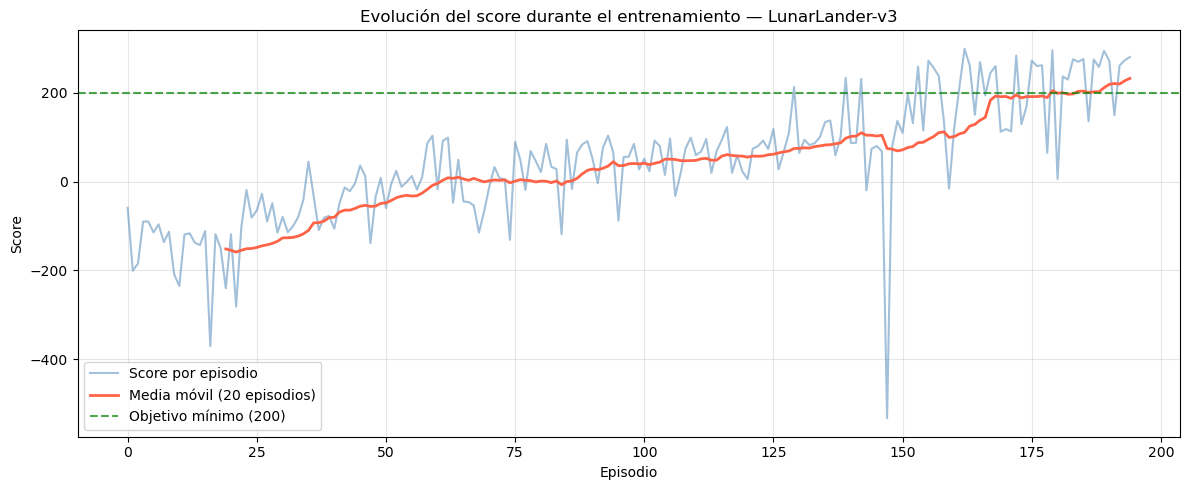

In [9]:
environment, number_of_observations, number_of_actions = create_environment()
number_of_observations = int(number_of_observations)
number_of_actions = int(number_of_actions)
agent = DQN(number_of_observations, number_of_actions)
episode = 0
start_time = time.perf_counter()
total_steps = 0
exploration_rate = EXPLORATION_RATE_MAX
goal_reached = False
average_score = 0

# --- WARM-UP: llenar el buffer con experiencias aleatorias antes de entrenar ---
print("Iniciando warm-up del buffer...")
warmup_state, info = environment.reset()
for _ in range(BATCH_SIZE * 35):  # 4480 transiciones aleatorias
    warmup_action = environment.action_space.sample()
    warmup_next, warmup_reward, warmup_terminal, warmup_truncated, info = environment.step(warmup_action)
    agent.remember(warmup_state, warmup_action, warmup_reward, warmup_next, warmup_terminal)
    if warmup_terminal or warmup_truncated:
        warmup_state, info = environment.reset()
    else:
        warmup_state = warmup_next
print(f"Warm-up completado: {agent.memory.current_size} transiciones almacenadas.")
# ------------------------------------------------------------------------------

while (episode < MAX_EPISODES_FOR_TRAINING) and not(goal_reached):
    episode += 1
    score = 0
    state, info = environment.reset()
    end_episode = False
    while not(end_episode):
        # Select an action for the current state
        action = agent.select_epsilon_greedy_policy(state, exploration_rate)

        # Execute the action on the environment
        state_next, reward, terminal_state, truncated, info = environment.step(action)

        total_steps += 1

        # Store in memory the transition (s,a,r,s')
        agent.remember(state, action, reward, state_next, terminal_state)

        score += reward

        # Learn using a batch of experience stored in memory
        if total_steps % TRAINING_FREQ == 0:
            agent.learn()

        # Hard update target network every TARGET_UPDATE_STEPS steps
        if total_steps % TARGET_UPDATE_STEPS == 0:
            agent.update_target_model()
        

        # Detect end of episode
        if terminal_state or truncated:
            end_episode = True
            agent.add_score(score)
            average_score = agent.average_score(EPISODES_TO_CHECK_TRAINING_GOAL)
            if average_score >= TRAINING_GOAL: goal_reached = True
            print("Episode {:>3}: ".format(episode), end='')
            print("score {:>8.1f} ".format(score), end='')
            print("(exploration rate: %.3f, " % exploration_rate, end='')
            print("average score: {:>6.1f}, ".format(average_score), end='')
            print("transitions: " + str(agent.memory.current_size) + ")")
        else:
            state = state_next


    # Decrease exploration rate
    exploration_rate *= EXPLORATION_RATE_DECAY
    exploration_rate = max(EXPLORATION_RATE_MIN, exploration_rate)

print("Time for training: ", end='')
print_time(time.perf_counter() - start_time)
print("Total steps: ", total_steps)
print("Score (average last episodes):", round(average_score))
print("Score (max):", round(max(agent.scores)))

agent.display_scores_graphically()

agent.save_model()

## Programa de prueba

Se evalúa la política greedy (sin exploración) durante `EPISODES_TO_EVALUATE_MODEL_PERFORMANCE` = 30 episodios y se calcula el score medio.

In [10]:
episode = 0
score_list = []
while (episode < EPISODES_TO_EVALUATE_MODEL_PERFORMANCE):
    episode += 1
    score = 0
    state, info = environment.reset()
    end_episode = False
    while not(end_episode):
        # Select an action for the current state
        action = agent.select_greedy_policy(state)

        # Execute the action in the environment
        state_next, reward, terminal_state, truncated, info = environment.step(action)

        score += reward
        state = state_next
        end_episode = terminal_state or truncated

    score_list.append(score)
    print("Episode {:>3}: ".format(episode), end='')
    print("score {:>8.1f} \n".format(score), end='')

print("Score (average):", round(np.mean(score_list)))

Episode   1: score    218.9 
Episode   2: score    258.7 
Episode   3: score    304.5 
Episode   4: score    155.8 
Episode   5: score    303.3 
Episode   6: score    283.2 
Episode   7: score    204.1 
Episode   8: score    251.8 
Episode   9: score    103.3 
Episode  10: score    252.4 
Episode  11: score    270.5 
Episode  12: score    249.6 
Episode  13: score    270.3 
Episode  14: score    263.8 
Episode  15: score    233.7 
Episode  16: score    277.9 
Episode  17: score    247.8 
Episode  18: score     24.8 
Episode  19: score    236.7 
Episode  20: score    279.6 
Episode  21: score    195.6 
Episode  22: score    250.8 
Episode  23: score    224.0 
Episode  24: score    257.4 
Episode  25: score    166.3 
Episode  26: score    235.3 
Episode  27: score    239.6 
Episode  28: score    268.0 
Episode  29: score    257.6 
Episode  30: score    300.4 
Score (average): 236


## Resultados de la ejecución final

### Resumen

| Métrica | Valor |
|---|---|
| **Pasos de entrenamiento** | 80 001 (más 4 480 del warm-up) |
| **Episodios de entrenamiento** | 195 |
| **Tiempo de entrenamiento** | 18 min 9 s |
| **Score medio (últimos 20 episodios de entrenamiento)** | 233 |
| **Score máximo en entrenamiento** | 299 |
| **Score medio en prueba (30 episodios, política greedy)** | **236** |
| **Episodios de prueba con score ≥ 200** | 25 de 30 |
| **Score mínimo / máximo en prueba** | 24.8 / 304.5 |

### Análisis

El agente supera con claridad el umbral de **200 puntos** de LunarLander-v3, con una media de **236** en los 30 episodios de prueba.

La **gráfica de entrenamiento** muestra tres fases:

1. **Exploración intensiva (episodios 1–50):** ε desciende de 1.0 a ≈ 0.48 y el agente actúa mayoritariamente al azar. El score medio es de -99, con valores entre -371 y 45, ya que el módulo se estrella con frecuencia o gasta combustible sin aterrizar.

2. **Aprendizaje (episodios 51–140):** el agente empieza a estabilizar el módulo. La media móvil de 20 episodios cruza el 0 hacia el episodio 62 y el 100 hacia el 141, aunque aún aparecen episodios muy negativos (hasta -533).

3. **Convergencia (episodios 141–195):** la media móvil supera los 200 puntos en el episodio 180 y el entrenamiento se detiene en el 195, con una media de 232.6 sobre los últimos 20 episodios (≥ 230).

La **red objetivo** contribuye a estabilizar los Q-targets durante todo el entrenamiento. En esta ejecución el **buffer circular** no llegó a sobrescribir transiciones, ya que se alcanzaron 84 481 de las 100 000 posibles; su comportamiento circular solo tendría efecto en entrenamientos más largos.

La evaluación muestra algo de variabilidad: 5 de los 30 episodios quedaron por debajo de 200 (155.8, 103.3, 24.8, 195.6 y 166.3), consecuencia del entorno estocástico y de que la política aún no es perfecta.


## Cambios probados que produjeron resultados insatisfactorios

Durante el desarrollo se probaron diversas configuraciones que no produjeron los resultados esperados:

### 1. Red neuronal con 3 capas ocultas (256-256-128)
Se probó añadir una tercera capa oculta de 128 neuronas. El entrenamiento fue más lento y no mejoró la puntuación final. La mayor capacidad del modelo no compensó el incremento en el tiempo de convergencia.

### 2. Decay de exploración muy lento (0.999)
Con un decay tan lento, el agente continuaba explorando aleatoriamente durante demasiados episodios, lo que retrasaba significativamente el aprendizaje. El agente tardaba cientos de episodios en empezar a explotar la política aprendida.

### 3. Decay de exploración muy rápido (0.98, igual que en CartPole)
El agente reducía su exploración demasiado pronto, antes de haber aprendido una política mínimamente útil para LunarLander. Esto provocaba que el agente quedase atrapado en políticas locales subóptimas.

### 4. Target network con actualización muy frecuente (cada 1 episodio, cuando la actualización se contaba por episodios)
Actualizar la red objetivo en cada episodio elimina prácticamente el beneficio de tenerla, ya que los Q-targets continúan siendo inestables. El rendimiento era similar al del DQN sin red objetivo.

### 5. Batch size pequeño (64) con red grande (256-256)
Con la red más grande, batches de 64 generaban gradientes muy ruidosos. Incrementar a 128 mejoró notablemente la estabilidad del entrenamiento.
